# AgriSense: Agricultural Price Prediction, Supply Analysis, and MSP Risk Assessment

This Google Colab notebook builds a responsible, reusable agricultural market intelligence pipeline from AGMARKNET-style CSV data.

It keeps four ideas separate throughout the workflow:

- **Observed data:** records present in the uploaded CSV.
- **Derived indicators:** cleaned columns, rolling summaries, lags, alerts, and historical rates.
- **Model predictions:** forecasts from trained models evaluated on held-out historical data.
- **Hypothetical scenarios:** transparent MSP/procurement tables that do not claim guaranteed price movement.

The source dataset usually contains market arrivals and prices, not directly measured consumer demand. Recorded arrivals are treated as a market supply proxy, not total regional supply or actual demand.


## 0. Colab Setup

In [62]:
# Install only the small set of packages used by this notebook.
!pip -q install joblib plotly xgboost gdown google-api-python-client


In [63]:
import json
import math
import os
from dataclasses import dataclass
from datetime import datetime, timezone
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except Exception:
    HAS_XGBOOST = False

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)
plt.style.use("seaborn-v0_8-whitegrid")

OUTPUT_DIR = Path("/content/agrisense_outputs") if Path("/content").exists() else Path.cwd() / "agrisense_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_VERSION = datetime.now(timezone.utc).strftime("agrisense-price-model-%Y%m%dT%H%M%SZ")
RANDOM_STATE = 42

print("Output directory:", OUTPUT_DIR)
print("Model version:", MODEL_VERSION)
print("XGBoost available:", HAS_XGBOOST)


Output directory: /content/agrisense_outputs
Model version: agrisense-price-model-20261014T124218Z
XGBoost available: True


## 1. Upload and Inspect the AGMARKNET CSV

In [64]:
# Load the AGMARKNET CSV from your shared Drive project, mounted Drive, or manual upload.
# If the automatic choice is not the right CSV, set CSV_PATH manually to one of the printed candidates and rerun this cell.
CSV_PATH = None
DRIVE_PROJECT_URL = "https://drive.google.com/drive/project/1FeqHzXNQZf-QHTcm8djk2kXxvwdZvRSz?usp=sharing"
DRIVE_FOLDER_ID = "1FeqHzXNQZf-QHTcm8djk2kXxvwdZvRSz"
DOWNLOAD_DIR = Path("/content/agrisense_drive_files") if Path("/content").exists() else Path.cwd() / "agrisense_drive_files"
CSV_NAME_HINTS = ["agmarknet", "price", "prices", "commodity", "market", "modal", "jind"]

def score_csv_candidate(path: Path) -> tuple:
    name = path.name.lower()
    hint_score = sum(1 for hint in CSV_NAME_HINTS if hint in name)
    try:
        size = path.stat().st_size
    except OSError:
        size = 0
    return (hint_score, size)

def find_csv_candidates(search_roots) -> List[Path]:
    candidates = []
    for root in search_roots:
        root = Path(root)
        if root.exists():
            candidates.extend(root.rglob("*.csv"))
    candidates = sorted(set(candidates), key=score_csv_candidate, reverse=True)
    return candidates

if CSV_PATH is not None:
    CSV_PATH = Path(CSV_PATH)

if CSV_PATH is None:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as exc:
        print("Drive mount is unavailable or already handled:", exc)

if CSV_PATH is None:
    mounted_candidates = find_csv_candidates([
        Path("/content/drive/MyDrive"),
        Path("/content/drive/Shareddrives"),
        Path.cwd(),
    ])
    if mounted_candidates:
        print("CSV candidates found in mounted/local storage:")
        for i, candidate in enumerate(mounted_candidates[:20]):
            print(f"[{i}] {candidate}")
        CSV_PATH = mounted_candidates[0]
        print("Automatically selected:", CSV_PATH)

if CSV_PATH is None:
    try:
        import gdown
        DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
        print("Trying to download CSV files from the shared Drive project/folder link...")
        for link in [DRIVE_PROJECT_URL, f"https://drive.google.com/drive/folders/{DRIVE_FOLDER_ID}"]:
            try:
                gdown.download_folder(url=link, output=str(DOWNLOAD_DIR), quiet=False, use_cookies=False)
            except Exception as exc:
                print(f"gdown could not read {link}: {exc}")
        downloaded_candidates = find_csv_candidates([DOWNLOAD_DIR])
        if downloaded_candidates:
            print("CSV candidates downloaded from Drive:")
            for i, candidate in enumerate(downloaded_candidates[:20]):
                print(f"[{i}] {candidate}")
            CSV_PATH = downloaded_candidates[0]
            print("Automatically selected:", CSV_PATH)
    except Exception as exc:
        print("Shared Drive download fallback failed:", exc)

if CSV_PATH is None:
    try:
        from google.colab import auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaIoBaseDownload
        import io

        print("Trying authenticated Google Drive API access to the shared project folder...")
        auth.authenticate_user()
        drive_service = build("drive", "v3")
        query = f"'{DRIVE_FOLDER_ID}' in parents and trashed = false"
        response = drive_service.files().list(
            q=query,
            fields="files(id, name, mimeType, size)",
            pageSize=1000,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True,
        ).execute()
        drive_files = response.get("files", [])
        csv_files = [f for f in drive_files if f["name"].lower().endswith(".csv")]
        if csv_files:
            csv_files = sorted(
                csv_files,
                key=lambda f: (sum(1 for hint in CSV_NAME_HINTS if hint in f["name"].lower()), int(f.get("size", 0))),
                reverse=True,
            )
            print("CSV candidates found through authenticated Drive API:")
            for i, item in enumerate(csv_files[:20]):
                print(f"[{i}] {item['name']} ({item['id']})")
            DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
            selected_file = csv_files[0]
            target_path = DOWNLOAD_DIR / selected_file["name"]
            request = drive_service.files().get_media(fileId=selected_file["id"], supportsAllDrives=True)
            with open(target_path, "wb") as output_file:
                downloader = MediaIoBaseDownload(output_file, request)
                done = False
                while not done:
                    _, done = downloader.next_chunk()
            CSV_PATH = target_path
            print("Automatically selected:", CSV_PATH)
    except Exception as exc:
        print("Authenticated Drive API fallback failed:", exc)

if CSV_PATH is None:
    try:
        from google.colab import files
        print("No CSV was found in Drive. Please upload the AGMARKNET CSV manually.")
        uploaded = files.upload()
        if uploaded:
            CSV_PATH = Path(next(iter(uploaded.keys())))
    except Exception as exc:
        print("Colab upload is unavailable in this environment:", exc)

if CSV_PATH is None:
    raise FileNotFoundError(
        "No CSV found. In Colab, either add the shared project folder as a shortcut to MyDrive, "
        "make the Drive folder link accessible, or set CSV_PATH manually to the AGMARKNET CSV path."
    )

CSV_PATH = Path(CSV_PATH)
df_raw = pd.read_csv(CSV_PATH)
print(f"Loaded {str(CSV_PATH)!r} with shape {df_raw.shape}")
display(df_raw.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV candidates found in mounted/local storage:
[0] /content/drive/MyDrive/agrisense_project/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv
[1] /content/drive/MyDrive/JIND_Variety-wise Daily Market Prices Data of Commodity (1).csv
[2] /content/drive/MyDrive/agmarknet_india_historical_prices_2024_2025.csv
[3] /content/drive/MyDrive/Agriculture_price_dataset_unclean_full_more_messy.csv
[4] /content/sample_data/mnist_train_small.csv
[5] /content/sample_data/mnist_test.csv
[6] /content/drive/MyDrive/8752174f-1d17-4aaf-8058-2eb396f50157.csv
[7] /content/sample_data/california_housing_train.csv
[8] /content/agrisense_outputs/agrisense_supply_analysis.csv
[9] /content/agrisense_outputs/agrisense_cleaned_dataset.csv
[10] /content/sample_data/california_housing_test.csv
[11] /content/drive/MyDrive/agrisense_project/weather-1.csv
[12] /content/drive/MyD

,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code
0,Haryana,Jind,Jind,Tomato,Other,FAQ,01/01/2025,1200,2000,1800.0,78
1,Haryana,Jind,Jind,Tomato,Other,FAQ,06/01/2025,700,1200,1100.0,78
2,Haryana,Jind,Jind,Tomato,Other,FAQ,12/01/2025,800,1300,1200.0,78
3,Haryana,Jind,Jind,Tomato,Other,FAQ,21/01/2025,800,1500,1400.0,78
4,Haryana,Jind,Jind,Tomato,Other,FAQ,24/01/2025,900,1200,1150.0,78


In [65]:
def inspect_uploaded_dataset(df: pd.DataFrame) -> Dict[str, object]:
    info = {
        "rows": int(len(df)),
        "columns": list(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "missing_values": df.isna().sum().sort_values(ascending=False),
        "dtypes": df.dtypes.astype(str),
    }

    print("Columns:")
    display(pd.DataFrame({"column": df.columns, "dtype": [str(df[c].dtype) for c in df.columns]}))

    print("\nRows:", info["rows"])
    print("Duplicate full rows:", info["duplicate_rows"])

    print("\nMissing values:")
    display(info["missing_values"].to_frame("missing_count"))

    numeric_summary = df.describe(include=[np.number]).T
    if not numeric_summary.empty:
        print("\nNumeric summary statistics:")
        display(numeric_summary)
    else:
        print("\nNo numeric columns detected before conversion.")

    object_summary = df.describe(include=["object"]).T if not df.select_dtypes(include=["object"]).empty else pd.DataFrame()
    if not object_summary.empty:
        print("\nText column summary:")
        display(object_summary)

    return info

dataset_info = inspect_uploaded_dataset(df_raw)


Columns:


,column,dtype
0,State,object
1,District,object
2,Market,object
3,Commodity,object
4,Variety,object
5,Grade,object
6,Arrival_Date,object
7,Min_Price,int64
8,Max_Price,int64
9,Modal_Price,float64



Rows: 10819
Duplicate full rows: 0

Missing values:


,missing_count
State,0
District,0
Market,0
Commodity,0
Variety,0
Grade,0
Arrival_Date,0
Min_Price,0
Max_Price,0
Modal_Price,0



Numeric summary statistics:


,count,mean,std,min,25%,50%,75%,max
Min_Price,10819.0,3293.204732,3115.176335,70.0,1000.0,2500.0,4000.0,20000.0
Max_Price,10819.0,3631.981884,3264.218552,120.0,1400.0,2600.0,4403.0,20000.0
Modal_Price,10819.0,3472.240169,3175.870843,120.0,1200.0,2500.0,4103.0,20000.0
Commodity_Code,10819.0,100.545060,119.481997,1.0,20.0,43.0,154.0,414.0



Text column summary:


,count,unique,top,freq
State,10819,1,Haryana,10819
District,10819,1,Jind,10819
Market,10819,14,Narwana,3008
Commodity,10819,41,Potato,1013
Variety,10819,44,Other,5499
Grade,10819,8,FAQ,4725
Arrival_Date,10819,471,01/11/2025,64


## 2. Column Mapping With User Confirmation

In [66]:

from typing import Dict, List, Optional, Tuple
import pandas as pd
from IPython.display import display

COLUMN_CANDIDATES = {
    "date": ["arrival_date", "arrival date", "date", "reported_date", "report_date"],
    "commodity": ["commodity", "crop", "item", "product", "commodity_name"],
    "market": ["market", "mandi", "market_name", "market center", "market_center"],
    "state": ["state", "state_name"],
    "district": ["district", "district_name"],
    "arrival_qty": ["arrival_quantity", "arrival quantity", "arrivals", "arrival_qty", "arrival qty", "quantity", "qty", "arrivals_qty"],
    "min_price": ["min_price", "min price", "minimum_price", "minimum price"],
    "max_price": ["max_price", "max price", "maximum_price", "maximum price"],
    "modal_price": ["modal_price", "modal price", "modal", "price", "modalprice"],
}

def normalize_column_name(name: str) -> str:
    return " ".join(str(name).strip().lower().replace("_", " ").replace("-", " ").split())

def suggest_column_mapping(df: pd.DataFrame) -> Tuple[Dict[str, Optional[str]], Dict[str, List[str]]]:
    normalized_to_original: Dict[str, List[str]] = {}
    for col in df.columns:
        normalized_to_original.setdefault(normalize_column_name(col), []).append(col)

    suggestions: Dict[str, Optional[str]] = {}
    ambiguous: Dict[str, List[str]] = {}
    for canonical, candidates in COLUMN_CANDIDATES.items():
        matches: List[str] = []
        for candidate in candidates:
            matches.extend(normalized_to_original.get(normalize_column_name(candidate), []))
        matches = list(dict.fromkeys(matches))
        suggestions[canonical] = matches[0] if len(matches) == 1 else None
        if len(matches) > 1:
            ambiguous[canonical] = matches
    return suggestions, ambiguous

suggested_mapping, ambiguous_mapping = suggest_column_mapping(df_raw)

print("Suggested mapping. Edit manual_mapping if any value is wrong or missing.")
display(pd.DataFrame(
    [{"standard_column": key, "suggested_source_column": value} for key, value in suggested_mapping.items()]
))

if ambiguous_mapping:
    print("\nAmbiguous columns found. Choose the correct source column in manual_mapping:")
    display(pd.DataFrame(
        [{"standard_column": key, "candidate_source_columns": ", ".join(value)} for key, value in ambiguous_mapping.items()]
    ))

# Populate manual_mapping below if any columns in df_raw were missed or ambiguous
manual_mapping = {
    # Example:
    # "date": "Arrival_Date",
    # "arrival_qty": "Arrival_Quantity",
    # "modal_price": "Modal_Price",
}

# Set to True to allow execution past the confirmation gate
CONFIRM_COLUMN_MAPPING = True

column_mapping = suggested_mapping.copy()
column_mapping.update({k: v for k, v in manual_mapping.items() if v})

required_columns = ["date", "commodity", "market", "modal_price"]
missing_required = [col for col in required_columns if not column_mapping.get(col)]
invalid_sources = [src for src in column_mapping.values() if src is not None and src not in df_raw.columns]

print("Final mapping candidate:")
display(pd.DataFrame([{"standard_column": k, "source_column": v} for k, v in column_mapping.items()]))

if missing_required:
    raise ValueError(f"Missing required mapping for: {missing_required}. Fill manual_mapping and rerun.")
if invalid_sources:
    raise ValueError(f"Mapped source columns not found in CSV: {invalid_sources}")
if not CONFIRM_COLUMN_MAPPING:
    raise ValueError("Review the displayed mapping, then set CONFIRM_COLUMN_MAPPING = True and rerun this cell.")

Suggested mapping. Edit manual_mapping if any value is wrong or missing.


,standard_column,suggested_source_column
0,date,Arrival_Date
1,commodity,Commodity
2,market,Market
3,state,State
4,district,District
5,arrival_qty,None
6,min_price,Min_Price
7,max_price,Max_Price
8,modal_price,Modal_Price


Final mapping candidate:


,standard_column,source_column
0,date,Arrival_Date
1,commodity,Commodity
2,market,Market
3,state,State
4,district,District
5,arrival_qty,None
6,min_price,Min_Price
7,max_price,Max_Price
8,modal_price,Modal_Price


## 3. Clean and Standardize the Data

In [67]:
def clean_text_series(series: pd.Series) -> pd.Series:
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})
    )

def to_numeric_safe(series: pd.Series) -> pd.Series:
    cleaned = series.astype("string").str.replace(",", "", regex=False).str.strip()
    return pd.to_numeric(cleaned, errors="coerce")

def season_from_month(month: int) -> str:
    if month in (12, 1, 2):
        return "Winter"
    if month in (3, 4, 5):
        return "Summer"
    if month in (6, 7, 8, 9):
        return "Monsoon"
    return "Post-Monsoon"

def iqr_outlier_flags(values: pd.Series) -> pd.Series:
    values = pd.to_numeric(values, errors="coerce")
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    if pd.isna(iqr) or iqr == 0:
        return pd.Series(False, index=values.index)
    return (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)

df = df_raw.copy()
rename_map = {source: standard for standard, source in column_mapping.items() if source}
df = df.rename(columns=rename_map)

for col in ["commodity", "market", "state", "district"]:
    if col in df.columns:
        df[col] = clean_text_series(df[col])

df["date"] = pd.to_datetime(df["date"], errors="coerce", dayfirst=True)

for col in ["arrival_qty", "min_price", "max_price", "modal_price"]:
    if col in df.columns:
        df[col] = to_numeric_safe(df[col])

df["record_id"] = np.arange(len(df))
df["flag_invalid_date"] = df["date"].isna()
df["flag_invalid_modal_price"] = df["modal_price"].isna() | (df["modal_price"] <= 0)

if "arrival_qty" in df.columns:
    df["flag_invalid_arrival_qty"] = df["arrival_qty"].isna() | (df["arrival_qty"] < 0)
else:
    df["arrival_qty"] = np.nan
    df["flag_invalid_arrival_qty"] = True

for col in ["min_price", "max_price"]:
    if col not in df.columns:
        df[col] = np.nan

df["flag_min_gt_modal"] = df["min_price"].notna() & df["modal_price"].notna() & (df["min_price"] > df["modal_price"])
df["flag_modal_gt_max"] = df["max_price"].notna() & df["modal_price"].notna() & (df["modal_price"] > df["max_price"])

series_id_cols = [col for col in ["commodity", "state", "district", "market"] if col in df.columns]
if "commodity" not in series_id_cols or "market" not in series_id_cols:
    raise ValueError("Cleaned data must include commodity and market columns.")

df["flag_price_outlier_iqr"] = (
    df.groupby(series_id_cols, dropna=False)["modal_price"].transform(iqr_outlier_flags).fillna(False)
)
df["flag_arrival_outlier_iqr"] = (
    df.groupby(series_id_cols, dropna=False)["arrival_qty"].transform(iqr_outlier_flags).fillna(False)
)

cleaning_summary = {
    "rows": len(df),
    "date_range_start": df["date"].min(),
    "date_range_end": df["date"].max(),
    "invalid_dates": int(df["flag_invalid_date"].sum()),
    "invalid_modal_prices": int(df["flag_invalid_modal_price"].sum()),
    "invalid_arrival_quantities": int(df["flag_invalid_arrival_qty"].sum()),
    "price_outlier_flags": int(df["flag_price_outlier_iqr"].sum()),
    "arrival_outlier_flags": int(df["flag_arrival_outlier_iqr"].sum()),
}

print("Cleaning summary:")
display(pd.Series(cleaning_summary).to_frame("value"))

print("Sample cleaned rows with flags:")
display(df.head(10))

print("Note: outliers are flagged for investigation and are not automatically deleted.")


Cleaning summary:


,value
rows,10819
date_range_start,2025-01-01 00:00:00
date_range_end,2026-04-20 00:00:00
invalid_dates,0
invalid_modal_prices,0
invalid_arrival_quantities,10819
price_outlier_flags,417
arrival_outlier_flags,0


Sample cleaned rows with flags:


,state,district,market,commodity,Variety,Grade,date,min_price,max_price,modal_price,Commodity_Code,record_id,flag_invalid_date,flag_invalid_modal_price,arrival_qty,flag_invalid_arrival_qty,flag_min_gt_modal,flag_modal_gt_max,flag_price_outlier_iqr,flag_arrival_outlier_iqr
0,Haryana,Jind,Jind,Tomato,Other,FAQ,2025-01-01,1200,2000,1800.0,78,0,False,False,NaN,True,False,False,False,False
1,Haryana,Jind,Jind,Tomato,Other,FAQ,2025-01-06,700,1200,1100.0,78,1,False,False,NaN,True,False,False,False,False
2,Haryana,Jind,Jind,Tomato,Other,FAQ,2025-01-12,800,1300,1200.0,78,2,False,False,NaN,True,False,False,False,False
3,Haryana,Jind,Jind,Tomato,Other,FAQ,2025-01-21,800,1500,1400.0,78,3,False,False,NaN,True,False,False,False,False
4,Haryana,Jind,Jind,Tomato,Other,FAQ,2025-01-24,900,1200,1150.0,78,4,False,False,NaN,True,False,False,False,False
5,Haryana,Jind,Jind,Tomato,Other,FAQ,2025-01-27,900,1200,1000.0,78,5,False,False,NaN,True,False,False,False,False
6,Haryana,Jind,Jind,Tomato,Other,FAQ,2025-01-28,800,1200,1150.0,78,6,False,False,NaN,True,False,False,False,False
7,Haryana,Jind,Jind,Potato,Other,FAQ,2025-01-09,1000,1150,1100.0,24,7,False,False,NaN,True,False,False,False,False
8,Haryana,Jind,Jind,Potato,Other,FAQ,2025-01-23,700,900,850.0,24,8,False,False,NaN,True,False,False,False,False
9,Haryana,Jind,Jind,Onion,Other,FAQ,2025-01-01,1500,2200,2150.0,23,9,False,False,NaN,True,False,False,False,False


Note: outliers are flagged for investigation and are not automatically deleted.


In [68]:
# Price and arrival units cannot be reliably inferred from all CSVs.
# Fill these from your dataset documentation or AGMARKNET export notes.
PRICE_UNIT = "Rs/quintal"      # Common AGMARKNET convention. Edit if your file uses a different unit.
ARRIVAL_UNIT = "tonnes"        # Common AGMARKNET convention. Edit if your file uses a different unit.

print("Price unit used in reports:", PRICE_UNIT)
print("Arrival quantity unit used in reports:", ARRIVAL_UNIT)


Price unit used in reports: Rs/quintal
Arrival quantity unit used in reports: tonnes


## 4. Reporting-Unit Check and Daily Panel Construction

In [69]:
# This check helps avoid accidental double counting before aggregating arrivals.
daily_key_cols = series_id_cols + ["date"]
candidate_duplicate_daily_records = (
    df.loc[~df["flag_invalid_date"], daily_key_cols + ["arrival_qty", "modal_price", "min_price", "max_price"]]
    .groupby(daily_key_cols, dropna=False)
    .size()
    .reset_index(name="records_per_day")
    .query("records_per_day > 1")
    .sort_values("records_per_day", ascending=False)
)

print("Series keys:", series_id_cols)
print("Potential repeated daily reporting keys:", len(candidate_duplicate_daily_records))
display(candidate_duplicate_daily_records.head(20))

REPORTING_UNIT_NOTE = (
    "The notebook aggregates records to one observation per series-date. "
    "Arrivals are summed only within the same series-date, and prices are arrival-weighted when valid arrival quantities exist; "
    "otherwise prices are averaged. Confirm this matches the CSV reporting unit before relying on aggregate arrivals."
)
print(REPORTING_UNIT_NOTE)


Series keys: ['commodity', 'state', 'district', 'market']
Potential repeated daily reporting keys: 64


,commodity,state,district,market,date,records_per_day
26,Apple,Haryana,Jind,Jind APMC,2025-12-18,2
46,Apple,Haryana,Jind,Jind APMC,2026-01-19,2
321,Apple,Haryana,Jind,Narwana APMC,2025-11-05,2
2494,Carrot,Haryana,Jind,Narwana APMC,2025-11-06,2
5629,Mousambi(Sweet Lime),Haryana,Jind,Safidon APMC,2025-11-16,2
5807,Mustard,Haryana,Jind,Safidon,2025-03-26,2
6164,Onion,Haryana,Jind,Jind APMC,2025-12-08,2
6827,Paddy(Basmati),Haryana,Jind,Jullana APMC,2025-11-01,2
6828,Paddy(Basmati),Haryana,Jind,Jullana APMC,2025-11-02,2
6829,Paddy(Basmati),Haryana,Jind,Jullana APMC,2025-11-04,2


The notebook aggregates records to one observation per series-date. Arrivals are summed only within the same series-date, and prices are arrival-weighted when valid arrival quantities exist; otherwise prices are averaged. Confirm this matches the CSV reporting unit before relying on aggregate arrivals.


In [70]:
def weighted_average(values: pd.Series, weights: pd.Series) -> float:
    valid = values.notna() & weights.notna() & (weights > 0)
    if valid.any():
        return float(np.average(values[valid], weights=weights[valid]))
    return float(values.mean()) if values.notna().any() else np.nan

valid_for_panel = df.loc[
    ~df["flag_invalid_date"] & ~df["flag_invalid_modal_price"],
    :
].copy()

def aggregate_daily(group: pd.DataFrame) -> pd.Series:
    weights = group["arrival_qty"] if "arrival_qty" in group.columns else pd.Series(np.nan, index=group.index)
    result = {
        "arrival_qty": group["arrival_qty"].sum(min_count=1),
        "modal_price": weighted_average(group["modal_price"], weights),
        "min_price": weighted_average(group["min_price"], weights),
        "max_price": weighted_average(group["max_price"], weights),
        "source_records": int(len(group)),
        "invalid_arrival_records": int(group["flag_invalid_arrival_qty"].sum()),
        "price_outlier_records": int(group["flag_price_outlier_iqr"].sum()),
        "arrival_outlier_records": int(group["flag_arrival_outlier_iqr"].sum()),
    }
    return pd.Series(result)

panel = (
    valid_for_panel
    .groupby(daily_key_cols, dropna=False)
    .apply(aggregate_daily)
    .reset_index()
    .sort_values(daily_key_cols)
)

panel["month"] = panel["date"].dt.month
panel["day_of_week"] = panel["date"].dt.dayofweek
panel["season"] = panel["month"].map(season_from_month)
panel["series_label"] = panel[series_id_cols].astype("string").agg(" | ".join, axis=1)

print("Daily panel shape:", panel.shape)
print("Date range:", panel["date"].min(), "to", panel["date"].max())
print("Number of commodity-market series:", panel["series_label"].nunique())
display(panel.head())


/tmp/ipykernel_29573/152876274.py:29: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



Daily panel shape: (10755, 17)
Date range: 2025-01-01 00:00:00 to 2026-04-20 00:00:00
Number of commodity-market series: 153


,commodity,state,district,market,date,arrival_qty,modal_price,min_price,max_price,source_records,invalid_arrival_records,price_outlier_records,arrival_outlier_records,month,day_of_week,season,series_label
0,Apple,Haryana,Jind,Jind APMC,2025-11-17,NaN,4000.0,2500.0,6000.0,1.0,1.0,0.0,0.0,11,0,Post-Monsoon,Apple | Haryana | Jind | Jind APMC
1,Apple,Haryana,Jind,Jind APMC,2025-11-18,NaN,4500.0,2500.0,6000.0,1.0,1.0,0.0,0.0,11,1,Post-Monsoon,Apple | Haryana | Jind | Jind APMC
2,Apple,Haryana,Jind,Jind APMC,2025-11-19,NaN,4000.0,2000.0,7000.0,1.0,1.0,0.0,0.0,11,2,Post-Monsoon,Apple | Haryana | Jind | Jind APMC
3,Apple,Haryana,Jind,Jind APMC,2025-11-20,NaN,4000.0,2000.0,7000.0,1.0,1.0,0.0,0.0,11,3,Post-Monsoon,Apple | Haryana | Jind | Jind APMC
4,Apple,Haryana,Jind,Jind APMC,2025-11-21,NaN,4000.0,2000.0,7000.0,1.0,1.0,0.0,0.0,11,4,Post-Monsoon,Apple | Haryana | Jind | Jind APMC


## 5. Supply Analysis

In [71]:
def add_supply_indicators(group: pd.DataFrame) -> pd.DataFrame:
    group = group.sort_values("date").copy()
    group["arrival_ma_7_obs"] = group["arrival_qty"].rolling(7, min_periods=2).mean()
    group["arrival_ma_30_obs"] = group["arrival_qty"].rolling(30, min_periods=5).mean()
    group["arrival_change"] = group["arrival_qty"].diff()
    previous_arrival = group["arrival_qty"].shift(1)
    group["arrival_pct_change"] = np.where(previous_arrival > 0, group["arrival_change"] / previous_arrival * 100, np.nan)
    std = group["arrival_qty"].std()
    if pd.isna(std) or std == 0:
        z = pd.Series(0.0, index=group.index)
    else:
        z = (group["arrival_qty"] - group["arrival_qty"].mean()) / std
    group["arrival_alert"] = np.select(
        [z >= 2, z <= -2],
        ["Unusually High", "Unusually Low"],
        default="Normal",
    )
    group["price_arrival_corr_to_date"] = group["modal_price"].expanding(min_periods=10).corr(group["arrival_qty"])
    return group

supply_panel = (
    panel.groupby(series_id_cols, dropna=False, group_keys=False)
    .apply(add_supply_indicators)
    .sort_values(daily_key_cols)
)

print("Supply indicators added. Recorded arrivals are a market supply proxy, not total regional supply.")
display(supply_panel.head(10))


Supply indicators added. Recorded arrivals are a market supply proxy, not total regional supply.


/tmp/ipykernel_29573/1010988109.py:23: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,commodity,state,district,market,date,arrival_qty,modal_price,min_price,max_price,source_records,invalid_arrival_records,price_outlier_records,arrival_outlier_records,month,day_of_week,season,series_label,arrival_ma_7_obs,arrival_ma_30_obs,arrival_change,arrival_pct_change,arrival_alert,price_arrival_corr_to_date
0,Apple,Haryana,Jind,Jind APMC,2025-11-17,NaN,4000.0,2500.0,6000.0,1.0,1.0,0.0,0.0,11,0,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN
1,Apple,Haryana,Jind,Jind APMC,2025-11-18,NaN,4500.0,2500.0,6000.0,1.0,1.0,0.0,0.0,11,1,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN
2,Apple,Haryana,Jind,Jind APMC,2025-11-19,NaN,4000.0,2000.0,7000.0,1.0,1.0,0.0,0.0,11,2,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN
3,Apple,Haryana,Jind,Jind APMC,2025-11-20,NaN,4000.0,2000.0,7000.0,1.0,1.0,0.0,0.0,11,3,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN
4,Apple,Haryana,Jind,Jind APMC,2025-11-21,NaN,4000.0,2000.0,7000.0,1.0,1.0,0.0,0.0,11,4,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN
5,Apple,Haryana,Jind,Jind APMC,2025-11-22,NaN,4000.0,2000.0,6800.0,1.0,1.0,0.0,0.0,11,5,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN
6,Apple,Haryana,Jind,Jind APMC,2025-11-24,NaN,4500.0,3000.0,7000.0,1.0,1.0,0.0,0.0,11,0,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN
7,Apple,Haryana,Jind,Jind APMC,2025-11-25,NaN,4500.0,3000.0,7000.0,1.0,1.0,0.0,0.0,11,1,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN
8,Apple,Haryana,Jind,Jind APMC,2025-11-26,NaN,5000.0,3000.0,7000.0,1.0,1.0,0.0,0.0,11,2,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN
9,Apple,Haryana,Jind,Jind APMC,2025-11-27,NaN,4500.0,3000.0,7000.0,1.0,1.0,0.0,0.0,11,3,Post-Monsoon,Apple | Haryana | Jind | Jind APMC,NaN,NaN,NaN,NaN,Normal,NaN


Selected series: Apple | Haryana | Jind | Jind APMC


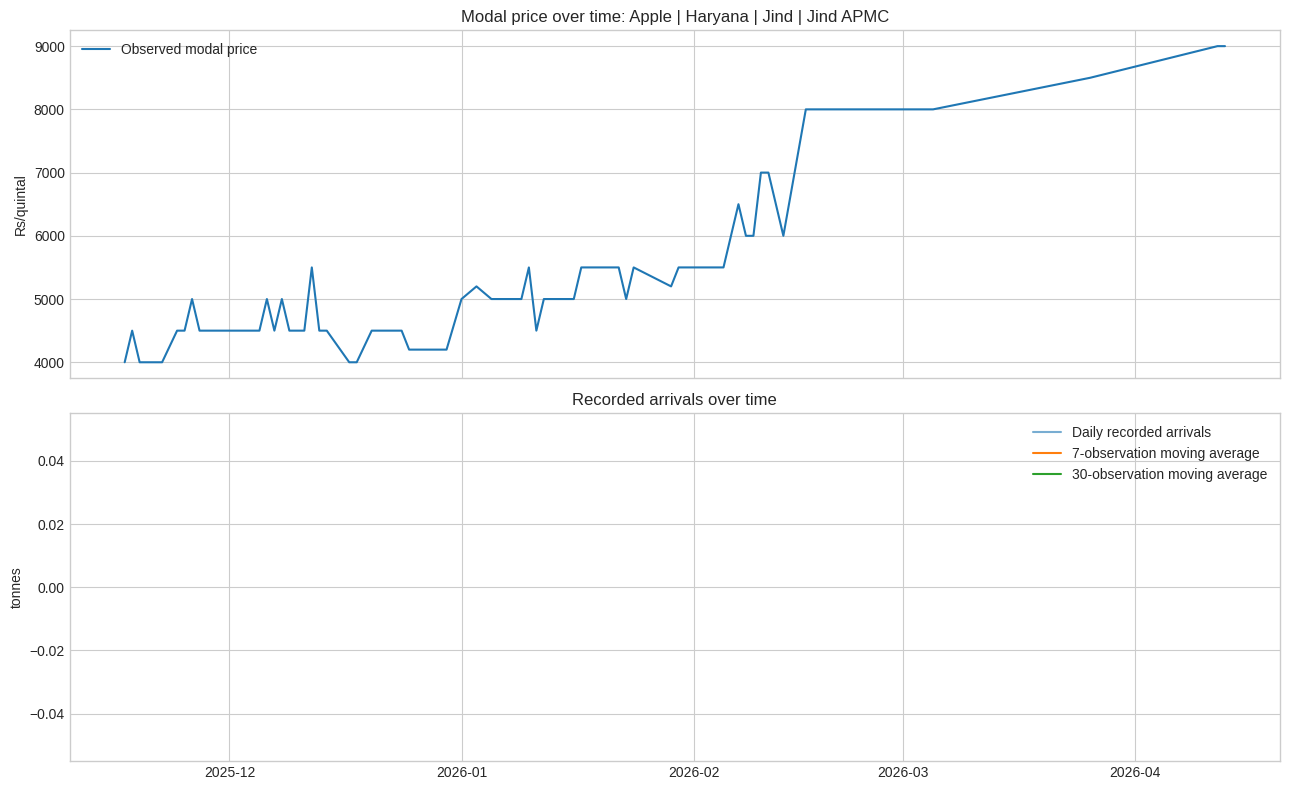

Interpretation note: historical correlation does not prove that arrivals caused price changes.


In [72]:
def plot_supply_and_price(data: pd.DataFrame, series_label: str) -> None:
    selected = data.loc[data["series_label"] == series_label].sort_values("date")
    if selected.empty:
        raise ValueError(f"No rows found for series_label={series_label!r}")

    fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
    axes[0].plot(selected["date"], selected["modal_price"], label="Observed modal price")
    axes[0].set_title(f"Modal price over time: {series_label}")
    axes[0].set_ylabel(PRICE_UNIT)
    axes[0].legend()

    axes[1].plot(selected["date"], selected["arrival_qty"], label="Daily recorded arrivals", alpha=0.6)
    axes[1].plot(selected["date"], selected["arrival_ma_7_obs"], label="7-observation moving average")
    axes[1].plot(selected["date"], selected["arrival_ma_30_obs"], label="30-observation moving average")
    axes[1].set_title("Recorded arrivals over time")
    axes[1].set_ylabel(ARRIVAL_UNIT)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

def plot_price_vs_arrivals(data: pd.DataFrame, series_label: str) -> None:
    selected = data.loc[data["series_label"] == series_label].sort_values("date")
    fig = px.scatter(
        selected,
        x="arrival_qty",
        y="modal_price",
        color="season",
        hover_data=["date"],
        title=f"Observed modal price versus recorded arrivals: {series_label}",
        labels={"arrival_qty": f"Arrival quantity ({ARRIVAL_UNIT})", "modal_price": f"Modal price ({PRICE_UNIT})"},
    )
    fig.show()
    print("Interpretation note: historical correlation does not prove that arrivals caused price changes.")

available_series = sorted(supply_panel["series_label"].dropna().unique())
SELECTED_SERIES_LABEL = available_series[0]
print("Selected series:", SELECTED_SERIES_LABEL)
plot_supply_and_price(supply_panel, SELECTED_SERIES_LABEL)
plot_price_vs_arrivals(supply_panel, SELECTED_SERIES_LABEL)


In [73]:
monthly_patterns = (
    supply_panel
    .groupby(series_id_cols + ["month", "season"], dropna=False)
    .agg(
        observations=("date", "count"),
        avg_arrival_qty=("arrival_qty", "mean"),
        median_arrival_qty=("arrival_qty", "median"),
        avg_modal_price=("modal_price", "mean"),
        median_modal_price=("modal_price", "median"),
    )
    .reset_index()
)

display(monthly_patterns.head(20))

selected_monthly = monthly_patterns.loc[
    monthly_patterns[series_id_cols].astype("string").agg(" | ".join, axis=1) == SELECTED_SERIES_LABEL
]

if len(selected_monthly) >= 3:
    fig = px.bar(
        selected_monthly,
        x="month",
        y="avg_arrival_qty",
        color="season",
        title=f"Seasonal arrival pattern: {SELECTED_SERIES_LABEL}",
        labels={"avg_arrival_qty": f"Average arrival quantity ({ARRIVAL_UNIT})"},
    )
    fig.show()
else:
    print("Not enough monthly observations for a seasonal arrival chart.")


,commodity,state,district,market,month,season,observations,avg_arrival_qty,median_arrival_qty,avg_modal_price,median_modal_price
0,Apple,Haryana,Jind,Jind APMC,1,Winter,17,NaN,NaN,5229.411765,5200.0
1,Apple,Haryana,Jind,Jind APMC,2,Winter,10,NaN,NaN,6350.000000,6000.0
2,Apple,Haryana,Jind,Jind APMC,3,Summer,2,NaN,NaN,8250.000000,8250.0
3,Apple,Haryana,Jind,Jind APMC,4,Summer,2,NaN,NaN,9000.000000,9000.0
4,Apple,Haryana,Jind,Jind APMC,11,Post-Monsoon,12,NaN,NaN,4333.333333,4500.0
5,Apple,Haryana,Jind,Jind APMC,12,Winter,24,NaN,NaN,4466.666667,4500.0
6,Apple,Haryana,Jind,Narwana,1,Winter,29,NaN,NaN,10275.862069,10000.0
7,Apple,Haryana,Jind,Narwana,2,Winter,27,NaN,NaN,11351.851852,11000.0
8,Apple,Haryana,Jind,Narwana,3,Summer,24,NaN,NaN,13270.833333,12750.0
9,Apple,Haryana,Jind,Narwana,4,Summer,20,NaN,NaN,14750.000000,15000.0


## 6. Past-Only Feature Engineering

In [74]:
def add_reporting_frequency(group: pd.DataFrame) -> pd.DataFrame:
    group = group.sort_values("date").copy()
    group["row_gap_days"] = group["date"].diff().dt.days
    median_gap = group["row_gap_days"].median()
    group["median_reporting_gap_days"] = median_gap if pd.notna(median_gap) else np.nan
    return group

frequency_panel = (
    supply_panel.groupby(series_id_cols, dropna=False, group_keys=False)
    .apply(add_reporting_frequency)
)

frequency_summary = (
    frequency_panel
    .groupby(series_id_cols, dropna=False)
    .agg(
        observations=("date", "count"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        median_reporting_gap_days=("median_reporting_gap_days", "median"),
        max_gap_days=("row_gap_days", "max"),
    )
    .reset_index()
)
frequency_summary["series_label"] = frequency_summary[series_id_cols].astype("string").agg(" | ".join, axis=1)

display(frequency_summary.sort_values("observations", ascending=False).head(20))
print("Lag features below are observation lags, not guaranteed calendar-day lags. Reporting gaps are shown above.")


/tmp/ipykernel_29573/2750465822.py:10: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,commodity,state,district,market,observations,first_date,last_date,median_reporting_gap_days,max_gap_days,series_label
12,Banana,Haryana,Jind,Safidon,269,2025-01-01,2025-11-05,1.0,3.0,Banana | Haryana | Jind | Safidon
1,Apple,Haryana,Jind,Narwana,251,2025-01-01,2025-11-04,1.0,7.0,Apple | Haryana | Jind | Narwana
3,Apple,Haryana,Jind,Safidon,250,2025-01-01,2025-11-05,1.0,6.0,Apple | Haryana | Jind | Safidon
134,Tomato,Haryana,Jind,Narwana,246,2025-01-01,2025-11-04,1.0,4.0,Tomato | Haryana | Jind | Narwana
123,Potato,Haryana,Jind,Narwana,236,2025-01-01,2025-11-04,1.0,5.0,Potato | Haryana | Jind | Narwana
86,Onion,Haryana,Jind,Narwana,235,2025-01-01,2025-11-04,1.0,7.0,Onion | Haryana | Jind | Narwana
84,Onion,Haryana,Jind,Jind,229,2025-01-01,2025-11-05,1.0,7.0,Onion | Haryana | Jind | Jind
121,Potato,Haryana,Jind,Jind,225,2025-01-01,2025-11-05,1.0,7.0,Potato | Haryana | Jind | Jind
125,Potato,Haryana,Jind,Safidon,223,2025-01-01,2025-11-04,1.0,9.0,Potato | Haryana | Jind | Safidon
132,Tomato,Haryana,Jind,Jind,215,2025-01-01,2025-11-05,1.0,10.0,Tomato | Haryana | Jind | Jind


Lag features below are observation lags, not guaranteed calendar-day lags. Reporting gaps are shown above.


In [75]:
PRICE_LAGS = [1, 2, 3, 7, 14]
ARRIVAL_LAGS = [1, 2, 3, 7, 14]
ROLLING_WINDOWS = [7, 30]

def engineer_features(group: pd.DataFrame) -> pd.DataFrame:
    group = group.sort_values("date").copy()
    group["target_modal_price"] = group["modal_price"]

    for lag in PRICE_LAGS:
        group[f"price_lag_{lag}"] = group["modal_price"].shift(lag)
    for lag in ARRIVAL_LAGS:
        group[f"arrival_lag_{lag}"] = group["arrival_qty"].shift(lag)

    for window in ROLLING_WINDOWS:
        group[f"price_roll_mean_{window}"] = group["modal_price"].shift(1).rolling(window, min_periods=2).mean()
        group[f"arrival_roll_mean_{window}"] = group["arrival_qty"].shift(1).rolling(window, min_periods=2).mean()

    group["month"] = group["date"].dt.month
    group["day_of_week"] = group["date"].dt.dayofweek
    group["season_code"] = group["month"].map(lambda month: {"Winter": 0, "Summer": 1, "Monsoon": 2, "Post-Monsoon": 3}[season_from_month(int(month))])
    group["source_records_lag_1"] = group["source_records"].shift(1)
    group["row_gap_days_lag_1"] = group["date"].diff().dt.days.shift(0)

    feature_columns = [
        *[f"price_lag_{lag}" for lag in PRICE_LAGS],
        *[f"arrival_lag_{lag}" for lag in ARRIVAL_LAGS],
        *[f"price_roll_mean_{window}" for window in ROLLING_WINDOWS],
        *[f"arrival_roll_mean_{window}" for window in ROLLING_WINDOWS],
        "month",
        "day_of_week",
        "season_code",
        "source_records_lag_1",
        "row_gap_days_lag_1",
    ]

    return group.dropna(subset=["target_modal_price"] + feature_columns).copy()

feature_panel = (
    frequency_panel.groupby(series_id_cols, dropna=False, group_keys=False)
    .apply(engineer_features)
    .sort_values(daily_key_cols)
)

FEATURE_COLUMNS = [
    *[f"price_lag_{lag}" for lag in PRICE_LAGS],
    *[f"arrival_lag_{lag}" for lag in ARRIVAL_LAGS],
    *[f"price_roll_mean_{window}" for window in ROLLING_WINDOWS],
    *[f"arrival_roll_mean_{window}" for window in ROLLING_WINDOWS],
    "month",
    "day_of_week",
    "season_code",
    "source_records_lag_1",
    "row_gap_days_lag_1",
]

print("Feature panel shape:", feature_panel.shape)
display(feature_panel[series_id_cols + ["date", "target_modal_price"] + FEATURE_COLUMNS].head())


Feature panel shape: (0, 43)


/tmp/ipykernel_29573/2763251812.py:40: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,commodity,state,district,market,date,target_modal_price,price_lag_1,price_lag_2,price_lag_3,price_lag_7,price_lag_14,arrival_lag_1,arrival_lag_2,arrival_lag_3,arrival_lag_7,arrival_lag_14,price_roll_mean_7,price_roll_mean_30,arrival_roll_mean_7,arrival_roll_mean_30,month,day_of_week,season_code,source_records_lag_1,row_gap_days_lag_1


## 7. Chronological Model Training and Evaluation

In [76]:
import math
from typing import Dict, List
from IPython.display import display
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Graceful XGBoost import check
try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

def chronological_split(group: pd.DataFrame, train_frac: float = 0.70, val_frac: float = 0.15):
    group = group.sort_values("date").copy()
    n = len(group)
    train_end = int(n * train_frac)
    val_end = int(n * (train_frac + val_frac))
    return group.iloc[:train_end], group.iloc[train_end:val_end], group.iloc[val_end:]

def regression_metrics(y_true, y_pred) -> Dict[str, float]:
    y_true = pd.Series(y_true).astype(float)
    y_pred = pd.Series(y_pred, index=y_true.index).astype(float)
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan,
    }

MIN_TRAINABLE_OBSERVATIONS = 80

model_registry: Dict[str, dict] = {}
evaluation_rows: List[dict] = []
test_predictions: List[pd.DataFrame] = []

# Ensure feature_panel is valid and date column is datetime
if not feature_panel.empty and "date" in feature_panel.columns:
    if not pd.api.types.is_datetime64_any_dtype(feature_panel["date"]):
        feature_panel["date"] = pd.to_datetime(feature_panel["date"])

for key_values, group in feature_panel.groupby(series_id_cols, dropna=False):
    if not isinstance(key_values, tuple):
        key_values = (key_values,)
    series_key = dict(zip(series_id_cols, key_values))
    series_label = " | ".join(str(series_key[col]) for col in series_id_cols)
    group = group.sort_values("date")

    if len(group) < MIN_TRAINABLE_OBSERVATIONS:
        evaluation_rows.append({
            **series_key,
            "series_label": series_label,
            "model": "Not trained",
            "status": f"Insufficient feature rows ({len(group)} < {MIN_TRAINABLE_OBSERVATIONS})",
            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "test_rows": 0,
        })
        continue

    train, val, test = chronological_split(group)
    if train.empty or val.empty or test.empty:
        evaluation_rows.append({
            **series_key,
            "series_label": series_label,
            "model": "Not trained",
            "status": "Chronological split produced an empty train, validation, or test set",
            "MAE": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "test_rows": len(test),
        })
        continue

    X_train = train[FEATURE_COLUMNS].astype(float)
    y_train = train["target_modal_price"].astype(float)
    X_test = test[FEATURE_COLUMNS].astype(float)
    y_test = test["target_modal_price"].astype(float)

    baseline_last = test["price_lag_1"].astype(float)
    baseline_roll7 = test["price_roll_mean_7"].astype(float)

    for model_name, prediction in [
        ("Baseline_LastObservedPrice", baseline_last),
        ("Baseline_7ObservationRollingMean", baseline_roll7),
    ]:
        metrics = regression_metrics(y_test, prediction)
        evaluation_rows.append({
            **series_key,
            "series_label": series_label,
            "model": model_name,
            "status": "evaluated",
            **metrics,
            "test_rows": len(test),
        })

    candidates = {}

    rf = RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    rf.fit(X_train, y_train)
    rf_pred = pd.Series(rf.predict(X_test), index=test.index)
    candidates["RandomForest"] = (rf, rf_pred)

    if HAS_XGBOOST:
        xgb_model = XGBRegressor(
            n_estimators=350,
            max_depth=4,
            learning_rate=0.04,
            subsample=0.9,
            colsample_bytree=0.9,
            random_state=RANDOM_STATE,
            objective="reg:squarederror",
        )
        xgb_model.fit(X_train, y_train)
        xgb_pred = pd.Series(xgb_model.predict(X_test), index=test.index)
        candidates["XGBoost"] = (xgb_model, xgb_pred)

    best_model_name = None
    best_mae = math.inf
    best_model = None

    for model_name, (model, prediction) in candidates.items():
        metrics = regression_metrics(y_test, prediction)
        evaluation_rows.append({
            **series_key,
            "series_label": series_label,
            "model": model_name,
            "status": "evaluated",
            **metrics,
            "test_rows": len(test),
        })
        if metrics["MAE"] < best_mae:
            best_mae = metrics["MAE"]
            best_model_name = model_name
            best_model = model

        test_predictions.append(pd.DataFrame({
            **series_key,
            "series_label": series_label,
            "date": test["date"].values,
            "actual_modal_price": y_test.values,
            "predicted_modal_price": prediction.values,
            "model": model_name,
        }))

    model_registry[series_label] = {
        "series_key": series_key,
        "best_model_name": best_model_name,
        "model": best_model,
        "feature_columns": FEATURE_COLUMNS,
        "training_rows": len(train),
        "validation_rows": len(val),
        "test_rows": len(test),
        "train_start": str(pd.to_datetime(train["date"].min()).date()),
        "train_end": str(pd.to_datetime(train["date"].max()).date()),
        "test_start": str(pd.to_datetime(test["date"].min()).date()),
        "test_end": str(pd.to_datetime(test["date"].max()).date()),
    }

# Ensure DataFrame has required columns even if evaluation_rows is empty
expected_columns = series_id_cols + ["series_label", "model", "status", "MAE", "RMSE", "R2", "test_rows"]

if evaluation_rows:
    evaluation_df = pd.DataFrame(evaluation_rows)
else:
    evaluation_df = pd.DataFrame(columns=expected_columns)

prediction_df = pd.concat(test_predictions, ignore_index=True) if test_predictions else pd.DataFrame()

print("Model evaluation results:")
if not evaluation_df.empty and "series_label" in evaluation_df.columns:
    display(evaluation_df.sort_values(["series_label", "MAE"], na_position="last"))
else:
    display(evaluation_df)
    print("Warning: No evaluations were generated. Check that 'feature_panel' is populated.")

if not model_registry:
    print("No series had enough data for ML training. Use the baseline and collect more historical observations.")

Model evaluation results:


,commodity,state,district,market,series_label,model,status,MAE,RMSE,R2,test_rows


No series had enough data for ML training. Use the baseline and collect more historical observations.


In [77]:
if not evaluation_df.empty:
    evaluated = evaluation_df.loc[evaluation_df["status"].eq("evaluated")].copy()
    if not evaluated.empty:
        fig = px.bar(
            evaluated.sort_values("MAE"),
            x="model",
            y="MAE",
            color="series_label",
            title="Model performance comparison by MAE",
            labels={"MAE": f"MAE ({PRICE_UNIT})"},
        )
        fig.show()

if not prediction_df.empty:
    plot_series_label = SELECTED_SERIES_LABEL if SELECTED_SERIES_LABEL in prediction_df["series_label"].unique() else prediction_df["series_label"].iloc[0]
    plot_predictions = prediction_df.loc[prediction_df["series_label"] == plot_series_label]
    fig = px.line(
        plot_predictions,
        x="date",
        y=["actual_modal_price", "predicted_modal_price"],
        color="model",
        title=f"Forecast versus actual on held-out test period: {plot_series_label}",
    )
    fig.show()


## 8. Forecasting Without Future Leakage

In [78]:
def infer_next_forecast_date(history: pd.DataFrame, step_number: int) -> pd.Timestamp:
    gaps = history.sort_values("date")["date"].diff().dt.days.dropna()
    step_days = int(max(1, gaps.mode().iloc[0])) if not gaps.empty else 1
    return history["date"].max() + pd.Timedelta(days=step_days * step_number)

def build_next_feature_row(history: pd.DataFrame, forecast_date: pd.Timestamp, assumed_arrival_qty: float) -> pd.DataFrame:
    prices = list(pd.Series(history["modal_price"]).astype(float))
    arrivals = list(pd.Series(history["arrival_qty"]).astype(float).ffill().fillna(0.0))
    source_records = list(pd.Series(history["source_records"]).astype(float).fillna(1.0))

    def lag(values: List[float], lag_n: int) -> float:
        return float(values[-lag_n]) if len(values) >= lag_n else np.nan

    row = {}
    for lag_n in PRICE_LAGS:
        row[f"price_lag_{lag_n}"] = lag(prices, lag_n)
    for lag_n in ARRIVAL_LAGS:
        row[f"arrival_lag_{lag_n}"] = lag(arrivals, lag_n)
    for window in ROLLING_WINDOWS:
        row[f"price_roll_mean_{window}"] = float(np.mean(prices[-window:])) if len(prices) >= 2 else np.nan
        row[f"arrival_roll_mean_{window}"] = float(np.mean(arrivals[-window:])) if len(arrivals) >= 2 else np.nan

    row["month"] = forecast_date.month
    row["day_of_week"] = forecast_date.dayofweek
    row["season_code"] = {"Winter": 0, "Summer": 1, "Monsoon": 2, "Post-Monsoon": 3}[season_from_month(forecast_date.month)]
    row["source_records_lag_1"] = source_records[-1] if source_records else 1.0
    row["row_gap_days_lag_1"] = max(1, int((forecast_date - history["date"].max()).days))

    return pd.DataFrame([row])[FEATURE_COLUMNS].astype(float)

def recursive_price_forecast(
    series_label: str,
    forecast_horizon_days: int,
    future_arrivals: Optional[List[float]] = None,
) -> pd.DataFrame:
    if series_label not in model_registry:
        raise ValueError(f"No trained model found for {series_label!r}. Check evaluation_df for data sufficiency.")

    registry_entry = model_registry[series_label]
    model = registry_entry["model"]
    history = supply_panel.loc[supply_panel["series_label"] == series_label].sort_values("date").copy()
    if history.empty:
        raise ValueError(f"No history found for {series_label!r}.")

    rows = []
    for step in range(1, forecast_horizon_days + 1):
        forecast_date = infer_next_forecast_date(history, step_number=1)
        if future_arrivals is not None and step - 1 < len(future_arrivals):
            assumed_arrival_qty = float(future_arrivals[step - 1])
        else:
            assumed_arrival_qty = float(history["arrival_qty"].ffill().iloc[-1])

        feature_row = build_next_feature_row(history, forecast_date, assumed_arrival_qty)
        predicted_price = float(model.predict(feature_row)[0])

        rows.append({
            "series_label": series_label,
            "forecast_date": forecast_date,
            "predicted_modal_price": predicted_price,
            "assumed_arrival_qty": assumed_arrival_qty,
            "arrival_assumption": "user_supplied" if future_arrivals is not None and step - 1 < len(future_arrivals) else "last_observed_arrival_carried_forward",
            "model": registry_entry["best_model_name"],
            "model_version": MODEL_VERSION,
        })

        new_history_row = history.iloc[-1].copy()
        new_history_row["date"] = forecast_date
        new_history_row["modal_price"] = predicted_price
        new_history_row["arrival_qty"] = assumed_arrival_qty
        new_history_row["source_records"] = 0
        history = pd.concat([history, pd.DataFrame([new_history_row])], ignore_index=True)

    return pd.DataFrame(rows)

FORECAST_SERIES_LABEL = next(iter(model_registry.keys())) if model_registry else SELECTED_SERIES_LABEL
FORECAST_HORIZON_DAYS = 7

forecast_df = recursive_price_forecast(FORECAST_SERIES_LABEL, FORECAST_HORIZON_DAYS) if model_registry else pd.DataFrame()
display(forecast_df)

if not forecast_df.empty:
    recent_history = supply_panel.loc[supply_panel["series_label"] == FORECAST_SERIES_LABEL].sort_values("date").tail(60)
    fig = px.line(
        pd.concat([
            recent_history[["date", "modal_price"]].rename(columns={"date": "date", "modal_price": "price"}).assign(kind="recent observed"),
            forecast_df[["forecast_date", "predicted_modal_price"]].rename(columns={"forecast_date": "date", "predicted_modal_price": "price"}).assign(kind="forecast"),
        ]),
        x="date",
        y="price",
        color="kind",
        title=f"Recent history and recursive forecast: {FORECAST_SERIES_LABEL}",
        labels={"price": f"Modal price ({PRICE_UNIT})"},
    )
    fig.show()


""


## 9. MSP Monitoring

In [79]:
# Enter official MSP values from a verified source. Do not invent MSP.
OFFICIAL_MSP = None        # Example: 2300.0
MSP_COMMODITY = None       # Example: "Paddy"
MSP_SEASON = None          # Example: "Kharif 2026-27"

def calculate_msp_report(
    series_label: str,
    official_msp: Optional[float],
    msp_commodity: Optional[str],
    msp_season: Optional[str],
    forecast: pd.DataFrame,
) -> pd.DataFrame:
    if official_msp is None or official_msp <= 0:
        print("Official MSP is missing. Enter OFFICIAL_MSP from a verified source before running MSP risk classification.")
        return pd.DataFrame()

    history = supply_panel.loc[supply_panel["series_label"] == series_label].sort_values("date")
    current_observed_price = float(history["modal_price"].iloc[-1]) if not history.empty else np.nan
    current_gap = official_msp - current_observed_price if pd.notna(current_observed_price) else np.nan
    current_gap_pct = current_gap / official_msp * 100 if official_msp else np.nan

    historical_below_msp_rate = (
        float((history["modal_price"] < official_msp).mean() * 100)
        if len(history) >= 20
        else np.nan
    )

    rows = [{
        "series_label": series_label,
        "record_type": "current_observed",
        "date": history["date"].iloc[-1] if not history.empty else pd.NaT,
        "official_msp": official_msp,
        "msp_commodity": msp_commodity,
        "msp_season": msp_season,
        "modal_price": current_observed_price,
        "price_gap": current_gap,
        "price_gap_pct": current_gap_pct,
        "below_msp": bool(current_observed_price < official_msp) if pd.notna(current_observed_price) else pd.NA,
        "historical_below_msp_rate_pct": historical_below_msp_rate,
    }]

    for _, row in forecast.iterrows():
        gap = official_msp - row["predicted_modal_price"]
        rows.append({
            "series_label": series_label,
            "record_type": "forecast",
            "date": row["forecast_date"],
            "official_msp": official_msp,
            "msp_commodity": msp_commodity,
            "msp_season": msp_season,
            "modal_price": row["predicted_modal_price"],
            "price_gap": gap,
            "price_gap_pct": gap / official_msp * 100,
            "below_msp": bool(row["predicted_modal_price"] < official_msp),
            "historical_below_msp_rate_pct": historical_below_msp_rate,
        })

    report = pd.DataFrame(rows)
    print("MSP note: MSP is not a guaranteed realized market price in every market, and modal prices may differ from farmer net realization after quality, commission, transport, and other deductions.")
    return report

msp_report_df = calculate_msp_report(
    FORECAST_SERIES_LABEL,
    OFFICIAL_MSP,
    MSP_COMMODITY,
    MSP_SEASON,
    forecast_df,
)
display(msp_report_df)

if not msp_report_df.empty:
    fig = px.line(
        msp_report_df,
        x="date",
        y=["modal_price", "official_msp"],
        color="record_type",
        title=f"MSP versus observed and forecast modal prices: {FORECAST_SERIES_LABEL}",
        labels={"value": PRICE_UNIT},
    )
    fig.show()


Official MSP is missing. Enter OFFICIAL_MSP from a verified source before running MSP risk classification.


""


## 10. Demand Estimation: Scientific Limitations

The uploaded AGMARKNET-style dataset contains market arrivals and price observations. It does not directly measure consumer demand.

Observed prices and traded quantities are jointly influenced by supply, demand, procurement, market structure, quality, storage, transport, and reporting practices. Because demand is not directly observed, this notebook does **not** create fabricated demand labels and does **not** train a supervised demand model from invented targets.

More credible demand estimation would need additional variables such as quantity actually sold, unsold stock, buyer purchases, government procurement quantities, consumer or processor purchases, inventory, regional production, arrivals from other markets, export movement, and independent demand indicators.


## 11. Transparent MSP Market-Absorption Scenario Simulator

In [80]:
CURRENT_MARKET_ARRIVALS = None                 # If None, uses latest observed arrival for FORECAST_SERIES_LABEL.
CURRENT_MODAL_PRICE = None                     # If None, uses latest observed modal price for FORECAST_SERIES_LABEL.
SCENARIO_MSP = OFFICIAL_MSP                   # Can be separate from OFFICIAL_MSP if needed.
HYPOTHETICAL_PURCHASE_QUANTITIES = [0, 25, 50, 100, 250, 500]

# Optional calibrated parameters. Leave as None unless independently estimated and validated.
CALIBRATED_PRICE_RESPONSE_PER_ABSORBED_UNIT = None

def run_market_absorption_scenario(
    series_label: str,
    current_arrivals: Optional[float],
    current_price: Optional[float],
    applicable_msp: Optional[float],
    purchase_quantities: List[float],
    calibrated_price_response_per_absorbed_unit: Optional[float] = None,
) -> pd.DataFrame:
    history = supply_panel.loc[supply_panel["series_label"] == series_label].sort_values("date")
    if history.empty:
        raise ValueError(f"No history for {series_label!r}")

    arrivals = float(current_arrivals) if current_arrivals is not None else float(history["arrival_qty"].ffill().iloc[-1])
    price = float(current_price) if current_price is not None else float(history["modal_price"].iloc[-1])

    rows = []
    for qty in purchase_quantities:
        qty = float(qty)
        absorbed_share = qty / arrivals * 100 if arrivals > 0 else np.nan
        remaining_recorded_arrivals = max(arrivals - qty, 0) if arrivals >= 0 else np.nan

        if calibrated_price_response_per_absorbed_unit is None:
            scenario_price = np.nan
            price_response_note = "No price response estimated because no calibrated demand/supply model was provided."
        else:
            scenario_price = price + qty * calibrated_price_response_per_absorbed_unit
            price_response_note = "Price response uses user-provided calibrated parameter; validate before decisions."

        rows.append({
            "series_label": series_label,
            "current_recorded_arrivals": arrivals,
            "current_modal_price": price,
            "applicable_msp": applicable_msp,
            "hypothetical_additional_quantity_purchased": qty,
            "absorbed_share_of_current_arrivals_pct": absorbed_share,
            "remaining_recorded_arrivals_after_purchase": remaining_recorded_arrivals,
            "scenario_predicted_price": scenario_price,
            "below_msp_after_scenario": bool(scenario_price < applicable_msp) if pd.notna(scenario_price) and applicable_msp else pd.NA,
            "assumption_note": price_response_note,
        })

    return pd.DataFrame(rows)

scenario_df = run_market_absorption_scenario(
    FORECAST_SERIES_LABEL,
    CURRENT_MARKET_ARRIVALS,
    CURRENT_MODAL_PRICE,
    SCENARIO_MSP,
    HYPOTHETICAL_PURCHASE_QUANTITIES,
    CALIBRATED_PRICE_RESPONSE_PER_ABSORBED_UNIT,
)
display(scenario_df)

print("Scenario limitation: this table explores hypothetical absorption quantities. It does not claim any purchase amount will guarantee MSP.")


,series_label,current_recorded_arrivals,current_modal_price,applicable_msp,hypothetical_additional_quantity_purchased,absorbed_share_of_current_arrivals_pct,remaining_recorded_arrivals_after_purchase,scenario_predicted_price,below_msp_after_scenario,assumption_note
0,Apple | Haryana | Jind | Jind APMC,NaN,9000.0,None,0.0,NaN,NaN,NaN,<NA>,No price response estimated because no calibra...
1,Apple | Haryana | Jind | Jind APMC,NaN,9000.0,None,25.0,NaN,NaN,NaN,<NA>,No price response estimated because no calibra...
2,Apple | Haryana | Jind | Jind APMC,NaN,9000.0,None,50.0,NaN,NaN,NaN,<NA>,No price response estimated because no calibra...
3,Apple | Haryana | Jind | Jind APMC,NaN,9000.0,None,100.0,NaN,NaN,NaN,<NA>,No price response estimated because no calibra...
4,Apple | Haryana | Jind | Jind APMC,NaN,9000.0,None,250.0,NaN,NaN,NaN,<NA>,No price response estimated because no calibra...
5,Apple | Haryana | Jind | Jind APMC,NaN,9000.0,None,500.0,NaN,NaN,NaN,<NA>,No price response estimated because no calibra...


Scenario limitation: this table explores hypothetical absorption quantities. It does not claim any purchase amount will guarantee MSP.


## 12. Export Cleaned Data, Analysis Tables, Model, and Metrics

In [81]:
cleaned_dataset_path = OUTPUT_DIR / "agrisense_cleaned_dataset.csv"
supply_analysis_path = OUTPUT_DIR / "agrisense_supply_analysis.csv"
evaluation_path = OUTPUT_DIR / "agrisense_model_evaluation.csv"
forecast_path = OUTPUT_DIR / "agrisense_forecast.csv"
msp_report_path = OUTPUT_DIR / "agrisense_msp_report.csv"
scenario_path = OUTPUT_DIR / "agrisense_msp_scenario_analysis.csv"
model_bundle_path = OUTPUT_DIR / f"{MODEL_VERSION}.joblib"

df.to_csv(cleaned_dataset_path, index=False)
supply_panel.to_csv(supply_analysis_path, index=False)
evaluation_df.to_csv(evaluation_path, index=False)
forecast_df.to_csv(forecast_path, index=False)
msp_report_df.to_csv(msp_report_path, index=False)
scenario_df.to_csv(scenario_path, index=False)

model_bundle = {
    "model_version": MODEL_VERSION,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "price_unit": PRICE_UNIT,
    "arrival_unit": ARRIVAL_UNIT,
    "series_id_cols": series_id_cols,
    "feature_columns": FEATURE_COLUMNS,
    "price_lags": PRICE_LAGS,
    "arrival_lags": ARRIVAL_LAGS,
    "rolling_windows": ROLLING_WINDOWS,
    "column_mapping": column_mapping,
    "reporting_unit_note": REPORTING_UNIT_NOTE,
    "models": model_registry,
    "evaluation": evaluation_df,
    "history_panel": supply_panel,
    "training_data_date_range": {
        "start": str(supply_panel["date"].min().date()) if not supply_panel.empty else None,
        "end": str(supply_panel["date"].max().date()) if not supply_panel.empty else None,
    },
}

joblib.dump(model_bundle, model_bundle_path)

print("Saved deliverables:")
for path in [
    cleaned_dataset_path,
    supply_analysis_path,
    evaluation_path,
    forecast_path,
    msp_report_path,
    scenario_path,
    model_bundle_path,
]:
    print("-", path)

try:
    from google.colab import files
    for path in [
        cleaned_dataset_path,
        supply_analysis_path,
        evaluation_path,
        forecast_path,
        msp_report_path,
        scenario_path,
        model_bundle_path,
    ]:
        files.download(str(path))
except Exception as exc:
    print("Automatic download is unavailable here. Files are saved in:", OUTPUT_DIR)


Saved deliverables:
- /content/agrisense_outputs/agrisense_cleaned_dataset.csv
- /content/agrisense_outputs/agrisense_supply_analysis.csv
- /content/agrisense_outputs/agrisense_model_evaluation.csv
- /content/agrisense_outputs/agrisense_forecast.csv
- /content/agrisense_outputs/agrisense_msp_report.csv
- /content/agrisense_outputs/agrisense_msp_scenario_analysis.csv
- /content/agrisense_outputs/agrisense-price-model-20261014T124218Z.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Reloadable Prediction Function for FastAPI Integration

In [82]:
def load_agrisense_model_bundle(path: str):
    return joblib.load(path)

def predict_from_saved_bundle(
    bundle: dict,
    request: dict,
    future_arrivals: Optional[List[float]] = None,
) -> dict:
    series_id_columns = bundle["series_id_cols"]
    history_panel = bundle["history_panel"].copy()
    models = bundle["models"]

    filters = []
    for col in series_id_columns:
        if col in request and request[col] is not None:
            filters.append(history_panel[col].astype("string").str.lower().eq(str(request[col]).lower()))

    if "series_label" in request and request["series_label"]:
        series_label = request["series_label"]
    else:
        if not filters:
            raise ValueError("Request must include series_label or enough commodity/state/district/market fields.")
        mask = np.logical_and.reduce(filters)
        matches = history_panel.loc[mask, "series_label"].dropna().unique()
        if len(matches) != 1:
            raise ValueError(f"Expected exactly one matching series, found {len(matches)}: {matches[:10]}")
        series_label = matches[0]

    if series_label not in models:
        raise ValueError(f"No trained model exists for {series_label!r}.")

    horizon = int(request.get("forecast_horizon_days", 1))
    if horizon < 1:
        raise ValueError("forecast_horizon_days must be at least 1.")

    registry_entry = models[series_label]
    model = registry_entry["model"]
    history = history_panel.loc[history_panel["series_label"] == series_label].sort_values("date").copy()

    forecasts = []
    for step in range(1, horizon + 1):
        forecast_date = infer_next_forecast_date(history, step_number=1)
        if future_arrivals is not None and step - 1 < len(future_arrivals):
            assumed_arrival_qty = float(future_arrivals[step - 1])
        else:
            assumed_arrival_qty = float(history["arrival_qty"].ffill().iloc[-1])
        feature_row = build_next_feature_row(history, forecast_date, assumed_arrival_qty)
        predicted_price = float(model.predict(feature_row)[0])
        forecasts.append({
            "forecast_date": str(forecast_date.date()),
            "predicted_modal_price": predicted_price,
            "price_unit": bundle["price_unit"],
            "assumed_arrival_qty": assumed_arrival_qty,
            "arrival_unit": bundle["arrival_unit"],
        })
        new_history_row = history.iloc[-1].copy()
        new_history_row["date"] = forecast_date
        new_history_row["modal_price"] = predicted_price
        new_history_row["arrival_qty"] = assumed_arrival_qty
        new_history_row["source_records"] = 0
        history = pd.concat([history, pd.DataFrame([new_history_row])], ignore_index=True)

    applicable_msp = request.get("applicable_msp")
    if applicable_msp is not None:
        applicable_msp = float(applicable_msp)
        for item in forecasts:
            item["applicable_msp"] = applicable_msp
            item["price_gap"] = applicable_msp - item["predicted_modal_price"]
            item["below_msp"] = item["predicted_modal_price"] < applicable_msp

    return {
        "series_label": series_label,
        "commodity": request.get("commodity"),
        "market": request.get("market"),
        "forecast_horizon_days": horizon,
        "model_name": registry_entry["best_model_name"],
        "model_version": bundle["model_version"],
        "forecasts": forecasts,
    }

example_request = {
    "commodity": "Paddy",
    "market": "Mandya",
    "forecast_horizon_days": 1,
    "applicable_msp": None,
}

print("Example FastAPI request body:")
print(json.dumps(example_request, indent=2))

print("\nExample FastAPI response shape:")
print(json.dumps({
    "series_label": "Paddy | Karnataka | Mandya | Mandya",
    "commodity": "Paddy",
    "market": "Mandya",
    "forecast_horizon_days": 1,
    "model_name": "RandomForest",
    "model_version": MODEL_VERSION,
    "forecasts": [{
        "forecast_date": "YYYY-MM-DD",
        "predicted_modal_price": 0.0,
        "price_unit": PRICE_UNIT,
        "applicable_msp": None,
        "price_gap": None,
    }],
}, indent=2))


Example FastAPI request body:
{
  "commodity": "Paddy",
  "market": "Mandya",
  "forecast_horizon_days": 1,
  "applicable_msp": null
}

Example FastAPI response shape:
{
  "series_label": "Paddy | Karnataka | Mandya | Mandya",
  "commodity": "Paddy",
  "market": "Mandya",
  "forecast_horizon_days": 1,
  "model_name": "RandomForest",
  "model_version": "agrisense-price-model-20261014T124218Z",
  "forecasts": [
    {
      "forecast_date": "YYYY-MM-DD",
      "predicted_modal_price": 0.0,
      "price_unit": "Rs/quintal",
      "applicable_msp": null,
      "price_gap": null
    }
  ]
}


## 14. FastAPI Integration Notes

Use the saved `.joblib` bundle in the AgriSense AI service instead of retraining for every prediction request.

Recommended service flow:

1. Load the model bundle once when the FastAPI process starts.
2. Validate the request commodity, market, and optional state/district against the saved `history_panel`.
3. Retrieve recent historical observations from the saved bundle or from your production market database.
4. Build past-only features from recent history.
5. Return the forecast, model version, price unit, and MSP gap only when an official MSP is supplied.

The saved model should not be expected to handle unseen commodities or markets unless you add explicit feature handling, fallback logic, or retrain with those series included.


## 15. Final Deliverables Checklist

After executing the notebook with a confirmed column mapping, the output folder contains:

- `agrisense_cleaned_dataset.csv`
- `agrisense_supply_analysis.csv`
- `agrisense_model_evaluation.csv`
- `agrisense_forecast.csv`
- `agrisense_msp_report.csv`
- `agrisense_msp_scenario_analysis.csv`
- a versioned `.joblib` model bundle
- a reusable Python prediction function for later FastAPI exposure

Review the model evaluation metrics before using forecasts operationally. Do not call the model accurate unless held-out test performance supports that claim.
